# __Project: Mandarin ASR with wav2vec 2.0 and CTC__

- This project follows the general workflow of the Hugging Face tutorial [Fine-Tuning XLS-R for Multilingual ASR with 🤗 Transformers](https://huggingface.co/blog/fine-tune-xlsr-wav2vec2). 

- The original tutorial has been adapted to the current Hugging Face Transformers API and to Mandarin speech recognition using the AISHELL-3 corpus.

- The goal of the project is to fine-tune a pretrained XLS-R model for Mandarin automatic speech recognition (ASR) using Connectionist Temporal Classification (CTC). Two output representations are investigated:

1. Chinese characters (Hanzi)
2. Tone-marked Pinyin syllables

- This notebook covers the forth part of the project, including the evaluation of the model's performance on the test set, also some further test on the model's bias.

- _AI-assisted development was used for code explanation, debugging, and API migration. Python version 3.13.14, Transformers version 5.12.1_

In [11]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------- ----------------------------- 2.4/9.3 MB 11.7 MB/s eta 0:00:01
   -------------------- ------------------- 4.7/9.3 MB 11.6 MB/s eta 0:00:01
   ------------------------------- -------- 7.3/9.3 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 11.5 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/3.0 MB ? eta -:--:--
   ------------------------------- -------- 2.4/3.0 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 3.0/3.0 MB 11.3 MB/s  0:00:00
Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl (7.3 MB)

   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----------------- ------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [12]:
import json
from pathlib import Path, PureWindowsPath

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from jiwer import wer
from matplotlib.ticker import PercentFormatter


In [13]:
PROJECT_ROOT = Path.cwd()
if (PROJECT_ROOT / "semester-project-chinese-ASR").is_dir():
    PROJECT_ROOT = PROJECT_ROOT / "semester-project-chinese-ASR"

TASKS = {
    "hanzi": ("Hanzi", "cer", "汉字"),
    "pinyin": ("Pinyin syllable", "wer", "带调音节"),
    "letter": ("Pinyin letter", "cer", "拼音字符和声调数字"),
}

run_dirs = {
    task: PROJECT_ROOT / "model_outputs" / task / "finetune_v2"
    for task in TASKS
}

summary_rows = []

for task, (name, metric_name, unit) in TASKS.items():
    metrics_path = run_dirs[task] / "test_metrics.json"

    if not metrics_path.is_file():
        print(f"跳过 {name}：找不到 {metrics_path}")
        continue

    summary = json.loads(metrics_path.read_text(encoding="utf-8"))
    checkpoint = summary.get("checkpoint")

    summary_rows.append({
        "模型": name,
        "Checkpoint": PureWindowsPath(checkpoint).name if checkpoint else "—",
        "测试条数": summary["num_examples"],
        "指标": metric_name.upper(),
        "评分单位": unit,
        "错误率": f"{summary['score']:.2%}",
    })

if summary_rows:
    display(pd.DataFrame(summary_rows))

跳过 Pinyin syllable：找不到 d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\pinyin\finetune_v2\test_metrics.json
跳过 Pinyin letter：找不到 d:\shuangpingpho\semester-project-chinese-ASR\model_outputs\letter\finetune_v2\test_metrics.json


,模型,Checkpoint,测试条数,指标,评分单位,错误率
0,Hanzi,checkpoint-7119,24773,CER,汉字,27.86%


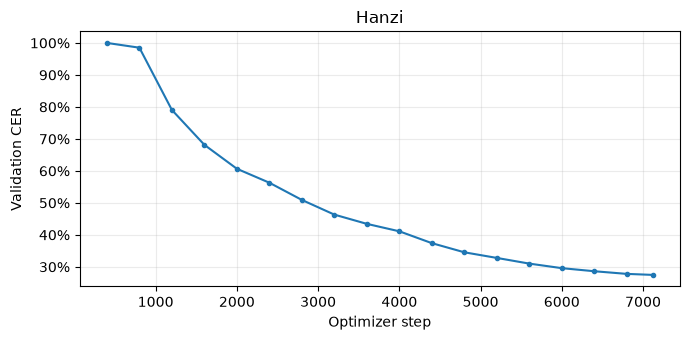

跳过 Pinyin syllable 的曲线：找不到 trainer_state.json
跳过 Pinyin letter 的曲线：找不到 trainer_state.json


In [14]:
for task, (name, metric_name, _) in TASKS.items():
    run_dir = run_dirs[task]
    state_path = run_dir / "trainer_state.json"

    if not state_path.is_file():
        states = [
            path
            for path in run_dir.glob("checkpoint-*/trainer_state.json")
            if path.parent.name.removeprefix("checkpoint-").isdigit()
        ]

        if not states:
            print(f"跳过 {name} 的曲线：找不到 trainer_state.json")
            continue

        state_path = max(
            states,
            key=lambda path: int(path.parent.name.removeprefix("checkpoint-")),
        )

    state = json.loads(state_path.read_text(encoding="utf-8"))
    metric_key = f"eval_{metric_name}"

    points = sorted(
        (entry["step"], entry[metric_key])
        for entry in state["log_history"]
        if "step" in entry and metric_key in entry
    )

    if not points:
        print(f"跳过 {name} 的曲线：日志里没有 {metric_key}")
        continue

    steps, scores = zip(*points)

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(steps, scores, marker="o", markersize=3)
    ax.set(
        title=name,
        xlabel="Optimizer step",
        ylabel=f"Validation {metric_name.upper()}",
    )
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()